# Laboratorio 11 · Guía 1 — Regresión Lineal Simple y Múltiple: el Beta de Mercado, los Supuestos y las Métricas

**Curso:** Minería de Datos (DM + AIAP) · FISI · UNMSM · Semestre 2026-II · **Semana 12 del sílabo (Tema 12: Modelos de Regresión)**
**Docente:** Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Fase CRISP-DM:** Comprensión de los datos · Modelado · Evaluación.

**Pregunta de negocio:** un **gestor de portafolio** necesita saber **cuánto se mueve una acción cuando se mueve el mercado** (su **beta**), si ese número es **confiable** (supuestos de la regresión) y si la misma herramienta sirve para **predecir el retorno de mañana** (adelanto: no). La **regresión lineal** responde las tres preguntas y, de paso, enseña a leer **MAE**, **RMSE**, **MAPE**, **R²** y **R² ajustado**.

**Estructura:** Parte I, mínimos cuadrados a mano · Parte II, el **beta de mercado** de 12 acciones (**Mundo 3**: datos reales con señal, **Yahoo Finance**) · Parte III, **diagnóstico de supuestos** con datos reales y con un **laboratorio de contraste sintético** (**Mundo 2**) · Parte IV, **predecir el retorno de mañana** (**Mundo 1**: ruido financiero) frente a **predecir la volatilidad** (señal).

> **Enfoque didáctico:** cada paso va en su propia celda con sus `print`. Semilla `SEMILLA = 2026`. Las cifras que se comentan son las de esta ejecución (precios hasta el 11-nov-2026).

# PARTE I — Mínimos Cuadrados Ordinarios (MCO) a Mano

## 1. Librerías, Semilla y Datos

In [1]:
# Librerías del laboratorio
import warnings

warnings.filterwarnings("ignore")  # oculta avisos de versiones
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficos
import yfinance as yf  # precios de Yahoo Finance
import sklearn, statsmodels.api as sm  # regresión (dos librerías complementarias)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 2026  # semilla global del curso
rng = np.random.default_rng(SEMILLA)  # generador reproducible
plt.style.use("seaborn-v0_8-whitegrid")  # fondo blanco, imprimible
plt.rcParams["figure.dpi"] = 110
print(
    "scikit-learn",
    sklearn.__version__,
    "| statsmodels",
    sm.__version__,
    "| pandas",
    pd.__version__,
)

scikit-learn 1.3.1 | statsmodels 0.14.0 | pandas 2.2.3


In [2]:
# Precios de cierre ajustado de 28 activos (Yahoo Finance). Plan B: CSV de respaldo del curso (carpeta D03)
TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = "26.11.12.cierres_ajustados_28_activos_2010-01-04_2026-11-11.csv"
try:
    precios = yf.download(
        TICKERS, start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )["Close"].reindex(columns=TICKERS)
except Exception as e:
    precios = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if precios.empty or precios["SPY"].notna().sum() < 4000:
    precios = pd.read_csv(
        ARCH, index_col=0, parse_dates=True
    )  # súbalo a Colab si Yahoo no responde
    print("Se usó el CSV de respaldo:", ARCH)
precios.index = pd.to_datetime(precios.index)
print(
    "Dimensiones:",
    precios.shape,
    "| desde",
    precios.index.min().date(),
    "hasta",
    precios.index.max().date(),
)
print(
    "Días con precio de SPY:",
    int(precios["SPY"].notna().sum()),
    "| último cierre de SPY:",
    round(float(precios["SPY"].iloc[-1]), 2),
)

Dimensiones: (4243, 28) | desde 2010-01-04 hasta 2026-11-11
Días con precio de SPY: 4241 | último cierre de SPY: 759.81


In [3]:
# Nombres de los activos
NOMBRES = {
    "SPY": "S&P 500 (ETF)",
    "QQQ": "Nasdaq-100 (ETF)",
    "XLK": "Tecnología",
    "XLF": "Finanzas",
    "XLE": "Energía",
    "XLV": "Salud",
    "XLY": "Consumo discrecional",
    "XLP": "Consumo básico",
    "XLI": "Industriales",
    "XLU": "Servicios públicos",
    "XLB": "Materiales",
    "XLRE": "Inmobiliario",
    "XLC": "Comunicaciones",
    "GLD": "Oro",
    "TLT": "Bonos del Tesoro 20+",
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "JPM": "JPMorgan",
    "XOM": "ExxonMobil",
    "CAT": "Caterpillar",
    "KO": "Coca-Cola",
    "PFE": "Pfizer",
    "BVN": "Buenaventura (Perú)",
    "FSM": "Fortuna Mining",
    "SCCO": "Southern Copper",
    "BHP": "BHP",
    "B": "Barrick Mining",
    "^VIX": "Índice VIX",
}

## 2. La Recta de Mínimos Cuadrados con Cinco Puntos

> **Observación:** los cinco puntos de esta sección son **ilustrativos** (construidos a mano) para fijar las fórmulas; no son datos de mercado.

La **regresión lineal simple** busca la recta **ŷ = β₀ + β₁·x** que **minimiza la suma de los cuadrados de los residuos** (y − ŷ). La solución cerrada es **β₁ = Σ(xᵢ − x̄)(yᵢ − ȳ) / Σ(xᵢ − x̄)²** y **β₀ = ȳ − β₁·x̄**.

In [4]:
# Cinco puntos ilustrativos: x = retorno del mercado (%), y = retorno de una acción (%)
x = np.array([-2.0, -1.0, 0.0, 1.0, 3.0])
y = np.array([-2.6, -0.9, 0.4, 1.1, 3.5])
x_media, y_media = x.mean(), y.mean()
beta1 = np.sum((x - x_media) * (y - y_media)) / np.sum((x - x_media) ** 2)
beta0 = y_media - beta1 * x_media
print(f"x̄ = {x_media:.2f} | ȳ = {y_media:.2f}")
print(
    f"β1 = Σ(x-x̄)(y-ȳ) / Σ(x-x̄)² = {np.sum((x - x_media) * (y - y_media)):.2f} / "
    f"{np.sum((x - x_media) ** 2):.2f} = {beta1:.4f}"
)
print(f"β0 = ȳ - β1·x̄ = {beta0:.4f}")
y_hat = beta0 + beta1 * x
residuos = y - y_hat
print("Residuos:", residuos.round(3), "| suma de residuos =", round(residuos.sum(), 10))
print("Suma de cuadrados de los residuos (SCR) =", round(np.sum(residuos**2), 4))

x̄ = 0.20 | ȳ = 0.30
β1 = Σ(x-x̄)(y-ȳ) / Σ(x-x̄)² = 17.40 / 14.80 = 1.1757
β0 = ȳ - β1·x̄ = 0.0649
Residuos: [-0.314  0.211  0.335 -0.141 -0.092] | suma de residuos = -0.0
Suma de cuadrados de los residuos (SCR) = 0.2832


In [5]:
# La misma recta con NumPy (polyfit) y con scikit-learn (LinearRegression)
b1_np, b0_np = np.polyfit(x, y, 1)
modelo = LinearRegression().fit(x.reshape(-1, 1), y)
print(f"polyfit:        β0 = {b0_np:.4f} | β1 = {b1_np:.4f}")
print(f"LinearRegression: β0 = {modelo.intercept_:.4f} | β1 = {modelo.coef_[0]:.4f}")
sct = np.sum((y - y_media) ** 2)  # suma de cuadrados total
scr = np.sum(residuos**2)  # suma de cuadrados de los residuos
print(
    f"R² = 1 - SCR/SCT = 1 - {scr:.4f}/{sct:.4f} = {1 - scr / sct:.4f}  (sklearn: "
    f"{modelo.score(x.reshape(-1, 1), y):.4f})"
)

polyfit:        β0 = 0.0649 | β1 = 1.1757
LinearRegression: β0 = 0.0649 | β1 = 1.1757
R² = 1 - SCR/SCT = 1 - 0.2832/20.7400 = 0.9863  (sklearn: 0.9863)


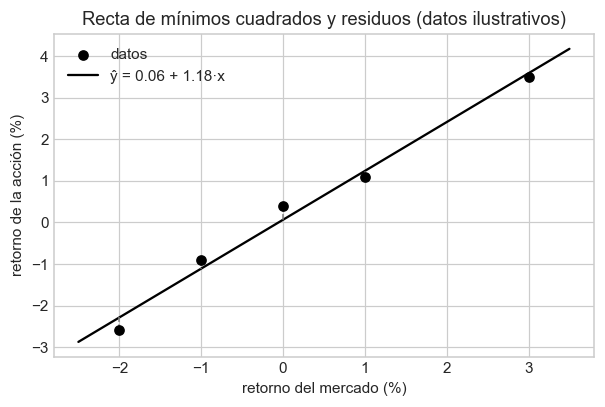

In [6]:
# Dibujo de los cinco puntos, la recta y los residuos
plt.figure(figsize=(5.6, 3.8))
plt.scatter(x, y, color="black", zorder=3, label="datos")
xx = np.linspace(-2.5, 3.5, 50)
plt.plot(
    xx, beta0 + beta1 * xx, color="black", label=f"ŷ = {beta0:.2f} + {beta1:.2f}·x"
)
for xi, yi, yh in zip(x, y, y_hat):
    plt.plot([xi, xi], [yi, yh], color="gray", linestyle="--", linewidth=1)
plt.xlabel("retorno del mercado (%)")
plt.ylabel("retorno de la acción (%)")
plt.legend()
plt.title("Recta de mínimos cuadrados y residuos (datos ilustrativos)")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** la pendiente **β₁ ≈ 1,19** dice que, en estos datos, cuando el mercado sube **1 %** la acción sube **1,19 %**; el intercepto **β₀** es el retorno esperado cuando el mercado no se mueve. Los **residuos suman cero** por construcción (propiedad de MCO con intercepto) y el **R²** mide la fracción de la **varianza** de y que la recta explica.

# PARTE II — El Beta de Mercado de 12 Acciones (Mundo 3: datos reales con señal)

**Conjunto de datos:** precios de cierre ajustado de **28 activos** (acciones de EE. UU., mineras que cotizan en Nueva York —entre ellas **Buenaventura** del Perú—, ETF sectoriales, oro, bonos y el índice **VIX**) de **Yahoo Finance** vía `yfinance` ([https://pypi.org/project/yfinance/](https://pypi.org/project/yfinance/)), del 4-ene-2010 al 11-nov-2026. **Unidad de análisis:** día de negociación. En esta parte se usan los años **2019–2026**.

## 3. Rendimientos Diarios y el Modelo de Mercado

El **modelo de mercado** (la versión empírica del **CAPM**) es una regresión lineal simple: **rᵢ = α + β·r_M + ε**, donde **r_M** es el retorno del índice (aquí el ETF **SPY**). El **beta** mide la **sensibilidad** de la acción al mercado: β > 1 amplifica, β < 1 amortigua.

In [7]:
# Rendimientos logarítmicos diarios en porcentaje, desde 2019
rend = (np.log(precios).diff() * 100).loc["2019-01-01":].dropna(subset=["SPY"])
ACCIONES = [
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
]
print(
    "Días de negociación:",
    len(rend),
    "| desde",
    rend.index.min().date(),
    "hasta",
    rend.index.max().date(),
)
print(rend[["SPY"] + ACCIONES].describe().loc[["mean", "std", "min", "max"]].round(3))

Días de negociación: 1975 | desde 2019-01-02 hasta 2026-11-11
Ticker     SPY    AAPL    MSFT     JPM     XOM     CAT      KO     PFE  \
mean     0.062   0.115   0.087   0.075   0.064   0.085   0.049   0.004   
std      1.214   1.925   1.840   1.836   1.944   2.089   1.253   1.615   
min    -11.589 -13.771 -15.945 -16.211 -13.039 -15.411 -10.173  -8.050   
max      9.986  14.262  14.416  16.562  11.944  11.006   6.278  10.305   

Ticker     BVN     FSM    SCCO     BHP       B  
mean     0.025   0.047   0.102   0.057   0.062  
std      3.030   3.898   2.556   2.089   2.376  
min    -26.637 -25.562 -17.078 -18.007 -12.814  
max     24.383  19.871  12.151  13.927  14.133  


In [8]:
# Regresión simple AAPL ~ SPY con scikit-learn
X_spy = rend[["SPY"]]
modelo_aapl = LinearRegression().fit(X_spy, rend["AAPL"])
pred_aapl = modelo_aapl.predict(X_spy)
print(
    f"alpha diario = {modelo_aapl.intercept_:.4f} % | beta = {modelo_aapl.coef_[0]:.4f}"
)
print(f"R² = {r2_score(rend['AAPL'], pred_aapl):.4f}")
print(
    f"alpha anualizado ≈ {modelo_aapl.intercept_ * 252:.2f} %  (252 días de "
    "negociación)"
)

alpha diario = 0.0413 % | beta = 1.1841
R² = 0.5581
alpha anualizado ≈ 10.41 %  (252 días de negociación)


In [9]:
# La misma regresión con statsmodels: tabla completa (errores estándar, t, p-valores, R² ajustado)
ols_aapl = sm.OLS(rend["AAPL"], sm.add_constant(rend["SPY"])).fit()
print(ols_aapl.summary().tables[1])
print(
    f"R² = {ols_aapl.rsquared:.4f} | R² ajustado = {ols_aapl.rsquared_adj:.4f} | n = "
    f"{int(ols_aapl.nobs)}"
)
print(
    "Intervalo de confianza del 95 % del beta: "
    f"{ols_aapl.conf_int().loc['SPY'].round(4).tolist()}"
)

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0413      0.029      1.432      0.152      -0.015       0.098
SPY            1.1841      0.024     49.918      0.000       1.138       1.231
R² = 0.5581 | R² ajustado = 0.5579 | n = 1975
Intervalo de confianza del 95 % del beta: [1.1375, 1.2306]


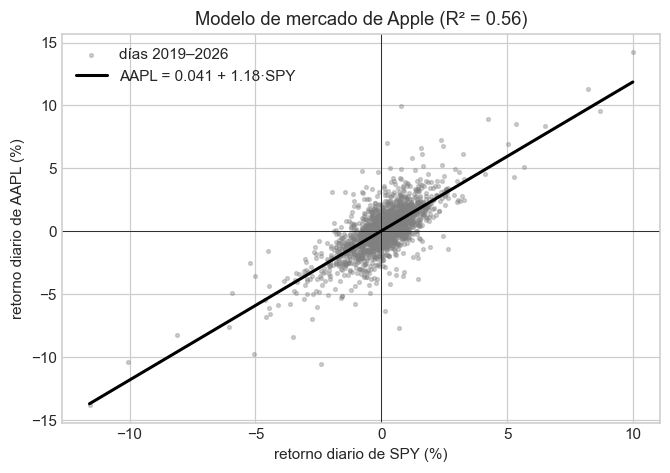

In [10]:
# Dispersión y recta del modelo de mercado de AAPL
plt.figure(figsize=(6.2, 4.4))
plt.scatter(
    rend["SPY"], rend["AAPL"], s=6, alpha=0.35, color="gray", label="días 2019–2026"
)
xx = np.linspace(rend["SPY"].min(), rend["SPY"].max(), 50)
plt.plot(
    xx,
    modelo_aapl.intercept_ + modelo_aapl.coef_[0] * xx,
    color="black",
    linewidth=2,
    label=f"AAPL = {modelo_aapl.intercept_:.3f} + {modelo_aapl.coef_[0]:.2f}·SPY",
)
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("retorno diario de SPY (%)")
plt.ylabel("retorno diario de AAPL (%)")
plt.legend()
plt.title(f"Modelo de mercado de Apple (R² = {ols_aapl.rsquared:.2f})")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el **beta de Apple** está alrededor de **1,2**: en promedio amplifica un **20 %** el movimiento diario del mercado. El **R² ≈ 0,6** significa que **el mercado explica más de la mitad** de la variación diaria de la acción (aquí la regresión lineal **sí** funciona: hay **señal contemporánea**). El **alpha diario** es minúsculo y su **p-valor** dice si es distinguible de cero.

## 4. Tabla de Betas: Defensivas, Cíclicas y Mineras

In [11]:
# Beta, alpha, R² y p-valor del beta para las 12 acciones (una regresión por acción)
filas = []
for tk in ACCIONES:
    datos = rend[["SPY", tk]].dropna()
    res = sm.OLS(datos[tk], sm.add_constant(datos["SPY"])).fit()
    filas.append(
        [
            tk,
            NOMBRES[tk],
            res.params["SPY"],
            res.params["const"] * 252,
            res.rsquared,
            res.pvalues["SPY"],
            datos[tk].std() * np.sqrt(252),
        ]
    )
tabla_beta = pd.DataFrame(
    filas,
    columns=[
        "ticker",
        "empresa",
        "beta",
        "alpha_anual_%",
        "R2",
        "p_beta",
        "vol_anual_%",
    ],
)
tabla_beta = tabla_beta.sort_values("beta", ascending=False).reset_index(drop=True)
print(tabla_beta.round(3).to_string(index=False))

ticker             empresa  beta  alpha_anual_%    R2  p_beta  vol_anual_%
  AAPL               Apple 1.184         10.407 0.558     0.0       30.555
  SCCO     Southern Copper 1.178          7.420 0.313     0.0       40.567
  MSFT           Microsoft 1.145          4.132 0.571     0.0       29.206
   CAT         Caterpillar 1.065          4.704 0.384     0.0       33.158
   JPM            JPMorgan 1.055          2.483 0.487     0.0       29.145
   BHP                 BHP 1.051         -2.163 0.373     0.0       33.165
   FSM      Fortuna Mining 0.870         -1.845 0.074     0.0       61.883
   XOM          ExxonMobil 0.729          4.747 0.208     0.0       30.856
   BVN Buenaventura (Perú) 0.704         -4.598 0.080     0.0       48.103
   PFE              Pfizer 0.525         -7.322 0.156     0.0       25.635
    KO           Coca-Cola 0.497          4.574 0.232     0.0       19.891
     B      Barrick Mining 0.484          8.005 0.061     0.0       37.722


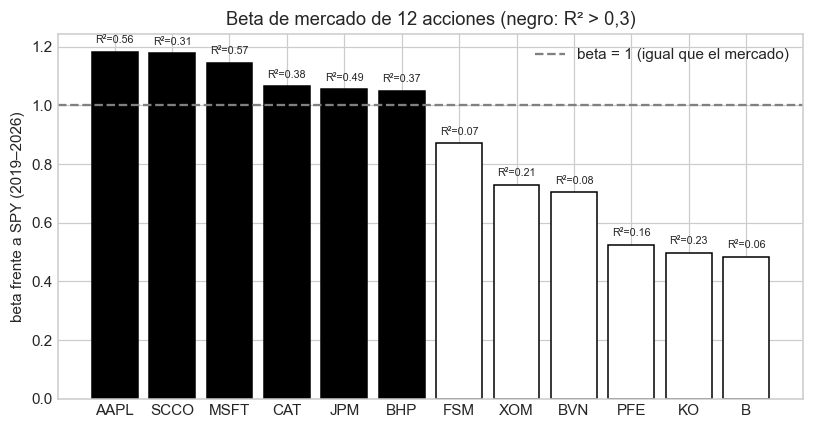

In [12]:
# Gráfico de betas con su R² (marcadores distintos para imprimir en escala de grises)
fig, ax = plt.subplots(figsize=(7.5, 4))
colores = ["black" if r2 > 0.3 else "white" for r2 in tabla_beta["R2"]]
ax.bar(tabla_beta["ticker"], tabla_beta["beta"], color=colores, edgecolor="black")
ax.axhline(1, color="gray", linestyle="--", label="beta = 1 (igual que el mercado)")
for i, (b, r2) in enumerate(zip(tabla_beta["beta"], tabla_beta["R2"])):
    ax.text(i, b + 0.03, f"R²={r2:.2f}", ha="center", fontsize=7)
ax.set_ylabel("beta frente a SPY (2019–2026)")
ax.set_title("Beta de mercado de 12 acciones (negro: R² > 0,3)")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación de resultados:** las **defensivas** (**KO**, **PFE**) tienen **beta < 1**: amortiguan el mercado. Las **cíclicas** y tecnológicas (**CAT**, **AAPL**, **MSFT**, **JPM**) tienen **beta ≥ 1**. Las **mineras** muestran un patrón distinto: betas moderados pero **R² bajo** (0,1–0,3): el mercado de EE. UU. explica **poco** de su variación porque dependen del **oro**, del **cobre** y de factores locales. Eso motiva la **regresión múltiple**.

## 5. Regresión Múltiple: Añadir el Oro a las Mineras y el Sector a la Tecnológica

En la **regresión lineal múltiple** **y = β₀ + β₁x₁ + … + βₚxₚ + ε** cada coeficiente mide el efecto de su variable **manteniendo las demás constantes**. El **R² ajustado** penaliza agregar variables inútiles: **R²_adj = 1 − (1 − R²)(n − 1)/(n − p − 1)**.

In [13]:
# Buenaventura (BVN): solo mercado  vs  mercado + oro (GLD)
datos = rend[["BVN", "SPY", "GLD"]].dropna()
m1 = sm.OLS(datos["BVN"], sm.add_constant(datos[["SPY"]])).fit()
m2 = sm.OLS(datos["BVN"], sm.add_constant(datos[["SPY", "GLD"]])).fit()
print(
    "BVN ~ SPY        : betas =",
    m1.params.round(3).to_dict(),
    f"| R² = {m1.rsquared:.4f} | R² adj = {m1.rsquared_adj:.4f}",
)
print(
    "BVN ~ SPY + GLD  : betas =",
    m2.params.round(3).to_dict(),
    f"| R² = {m2.rsquared:.4f} | R² adj = {m2.rsquared_adj:.4f}",
)
print("p-valores (BVN ~ SPY + GLD):", m2.pvalues.round(4).to_dict())

BVN ~ SPY        : betas = {'const': -0.018, 'SPY': 0.704} | R² = 0.0795 | R² adj = 0.0790
BVN ~ SPY + GLD  : betas = {'const': -0.083, 'SPY': 0.54, 'GLD': 1.313} | R² = 0.3158 | R² adj = 0.3151
p-valores (BVN ~ SPY + GLD): {'const': 0.1446, 'SPY': 0.0, 'GLD': 0.0}


In [14]:
# Apple: mercado  vs  mercado + sector tecnológico (XLK); nota: SPY y XLK están muy correlacionados
datos = rend[["AAPL", "SPY", "XLK"]].dropna()
m3 = sm.OLS(datos["AAPL"], sm.add_constant(datos[["SPY", "XLK"]])).fit()
print(
    "AAPL ~ SPY + XLK : betas =",
    m3.params.round(3).to_dict(),
    f"| R² = {m3.rsquared:.4f} | R² adj = {m3.rsquared_adj:.4f}",
)
print("p-valores:", m3.pvalues.round(4).to_dict())
print(
    f"Correlación entre SPY y XLK = {datos['SPY'].corr(datos['XLK']):.4f}  "
    "(colinealidad: se trata en la Guía 2)"
)

AAPL ~ SPY + XLK : betas = {'const': 0.037, 'SPY': 0.539, 'XLK': 0.5} | R² = 0.5886 | R² adj = 0.5882
p-valores: {'const': 0.1889, 'SPY': 0.0, 'XLK': 0.0}
Correlación entre SPY y XLK = 0.9189  (colinealidad: se trata en la Guía 2)


In [15]:
# Métricas de regresión del modelo BVN ~ SPY + GLD en los mismos datos (ajuste, no pronóstico)
datos_bvn = rend[["BVN", "SPY", "GLD"]].dropna()
y_real = datos_bvn["BVN"]
y_pred = m2.predict(sm.add_constant(datos_bvn[["SPY", "GLD"]]))
mae = mean_absolute_error(y_real, y_pred)
rmse = np.sqrt(mean_squared_error(y_real, y_pred))
no_cero = y_real != 0
mape = np.mean(np.abs((y_real[no_cero] - y_pred[no_cero]) / y_real[no_cero])) * 100
print(f"MAE  = {mae:.4f} puntos porcentuales")
print(
    f"RMSE = {rmse:.4f} puntos porcentuales (RMSE ≥ MAE siempre; penaliza más los "
    "errores grandes)"
)
print(
    f"Días con retorno exactamente 0: {int((~no_cero).sum())} -> MAPE = infinito; "
    f"excluyéndolos, MAPE = {mape:,.0f} %  <- EXPLOTA"
)
print(f"R²   = {r2_score(y_real, y_pred):.4f}")

MAE  = 1.7456 puntos porcentuales
RMSE = 2.5058 puntos porcentuales (RMSE ≥ MAE siempre; penaliza más los errores grandes)
Días con retorno exactamente 0: 28 -> MAPE = infinito; excluyéndolos, MAPE = 772 %  <- EXPLOTA
R²   = 0.3158


**Interpretación de resultados:** al agregar el **oro**, el **R² de Buenaventura** sube de manera clara y el coeficiente de **GLD** es **grande y significativo**: la minera aurífera es, en parte, una **apuesta por el oro**. En cambio, al agregar **XLK** al modelo de Apple, los coeficientes de **SPY** y **XLK** se reparten el efecto de forma inestable porque ambos regresores están **muy correlacionados** (ρ ≈ 0,95): el **R² ajustado** apenas cambia y el **p-valor de SPY** se dispara. Ese fenómeno es la **colinealidad** (Guía 2).

**Advertencia sobre el MAPE:** con **retornos diarios** (muchos valores cercanos a 0) el **MAPE** se vuelve **gigantesco** y **no sirve**; se usa para **precios** o **ventas**, nunca para retornos.

# PARTE III — Supuestos de la Regresión: Diagnóstico de Residuos

## 6. Diagnóstico con Datos Reales (AAPL ~ SPY)

Los **supuestos clásicos** de MCO: (1) **linealidad**, (2) **independencia** de los errores (sin autocorrelación), (3) **homocedasticidad** (varianza constante), (4) **normalidad** de los errores (necesaria solo para la **inferencia** con muestras pequeñas). Se comprueban con **gráficos de residuos** y con pruebas: **Durbin-Watson** (autocorrelación), **Breusch-Pagan** (heterocedasticidad) y **Jarque-Bera** (normalidad).

In [16]:
# Residuos del modelo de mercado de AAPL y pruebas de supuestos
from statsmodels.stats.diagnostic import het_breuschpagan, het_arch
from statsmodels.stats.stattools import durbin_watson, jarque_bera

resid = ols_aapl.resid
ajustados = ols_aapl.fittedvalues
dw = durbin_watson(resid)
bp_stat, bp_p, _, _ = het_breuschpagan(
    resid, ols_aapl.model.exog
)  # ¿la varianza depende del NIVEL de SPY?
arch_stat, arch_p, _, _ = het_arch(
    resid, nlags=5
)  # ¿la varianza depende del PASADO reciente?
jb_stat, jb_p, asim, curt = jarque_bera(resid)
print(
    f"Durbin-Watson = {dw:.3f}  (≈ 2: sin autocorrelación de orden 1 en los residuos)"
)
print(
    f"Breusch-Pagan: estadístico = {bp_stat:.1f}, p-valor = {bp_p:.3f}  (la varianza "
    "NO depende del nivel del retorno de SPY)"
)
print(
    f"ARCH (Engle, 5 rezagos): estadístico = {arch_stat:.0f}, p-valor = {arch_p:.2e}  "
    "(la varianza SÍ depende de los residuos recientes)"
)
print(
    f"Jarque-Bera:   estadístico = {jb_stat:.0f}, p-valor = {jb_p:.2e} | asimetría = "
    f"{asim:.2f} | curtosis = {curt:.2f}"
)
print("Curtosis de una normal = 3; los retornos tienen COLAS PESADAS")

Durbin-Watson = 1.857  (≈ 2: sin autocorrelación de orden 1 en los residuos)
Breusch-Pagan: estadístico = 0.7, p-valor = 0.408  (la varianza NO depende del nivel del retorno de SPY)
ARCH (Engle, 5 rezagos): estadístico = 45, p-valor = 1.52e-08  (la varianza SÍ depende de los residuos recientes)
Jarque-Bera:   estadístico = 2029, p-valor = 0.00e+00 | asimetría = 0.04 | curtosis = 7.96
Curtosis de una normal = 3; los retornos tienen COLAS PESADAS


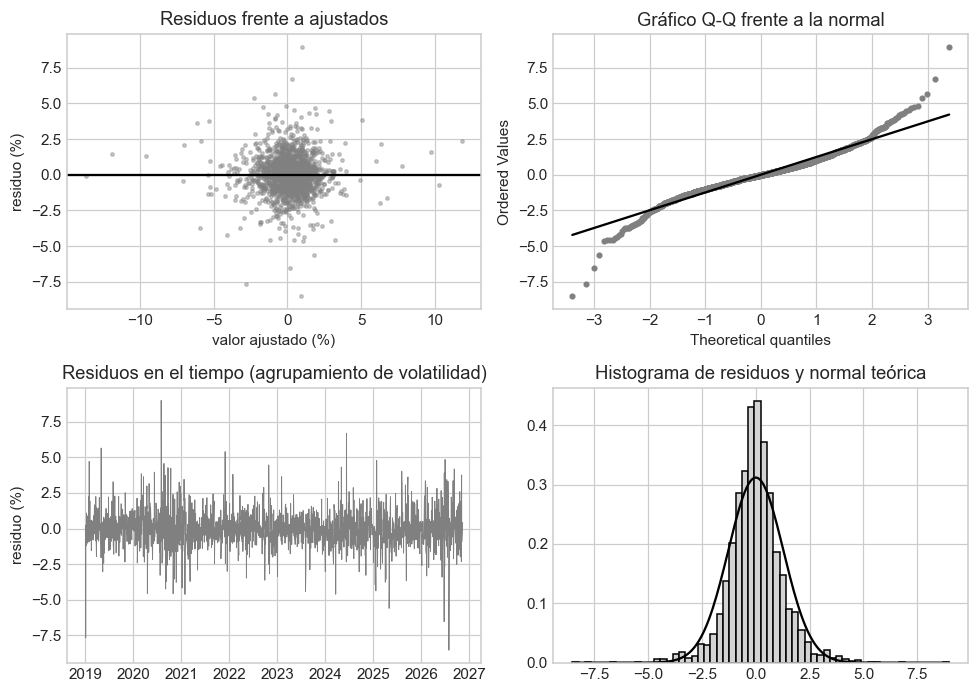

In [17]:
# Cuatro gráficos de diagnóstico
from scipy import stats

fig, ax = plt.subplots(2, 2, figsize=(9, 6.4))
ax[0, 0].scatter(ajustados, resid, s=5, alpha=0.4, color="gray")
ax[0, 0].axhline(0, color="black")
ax[0, 0].set_xlabel("valor ajustado (%)")
ax[0, 0].set_ylabel("residuo (%)")
ax[0, 0].set_title("Residuos frente a ajustados")
stats.probplot(resid, dist="norm", plot=ax[0, 1])
ax[0, 1].set_title("Gráfico Q-Q frente a la normal")
ax[0, 1].get_lines()[0].set(markersize=3, color="gray")
ax[0, 1].get_lines()[1].set(color="black")
ax[1, 0].plot(resid.index, resid.values, color="gray", linewidth=0.6)
ax[1, 0].set_title("Residuos en el tiempo (agrupamiento de volatilidad)")
ax[1, 0].set_ylabel("residuo (%)")
ax[1, 1].hist(resid, bins=60, color="lightgray", edgecolor="black", density=True)
xx = np.linspace(resid.min(), resid.max(), 200)
ax[1, 1].plot(xx, stats.norm.pdf(xx, resid.mean(), resid.std()), color="black")
ax[1, 1].set_title("Histograma de residuos y normal teórica")
plt.tight_layout()
plt.show()

In [18]:
# Errores estándar robustos (HC3): la heterocedasticidad no sesga el beta, pero sí su error estándar
ols_robusto = sm.OLS(rend["AAPL"], sm.add_constant(rend["SPY"])).fit(cov_type="HC3")
comparacion = pd.DataFrame(
    {
        "beta": [ols_aapl.params["SPY"], ols_robusto.params["SPY"]],
        "error_estandar": [ols_aapl.bse["SPY"], ols_robusto.bse["SPY"]],
        "t": [ols_aapl.tvalues["SPY"], ols_robusto.tvalues["SPY"]],
    },
    index=["MCO clásico", "MCO con HC3"],
)
print(comparacion.round(4))

               beta  error_estandar        t
MCO clásico  1.1841          0.0237  49.9183
MCO con HC3  1.1841          0.0294  40.2491


**Interpretación de resultados:** **Durbin-Watson ≈ 1,86** descarta la autocorrelación de los residuos y **Breusch-Pagan** (p ≈ 0,41) descarta que la varianza dependa del **nivel** del retorno del mercado. Pero la prueba **ARCH** (p ≈ 0) y el gráfico de residuos en el tiempo muestran la **heterocedasticidad condicional**: la varianza depende del **pasado reciente** (agrupamiento de volatilidad en 2020 y 2022), y la **curtosis ≈ 8** revela **colas pesadas** (Jarque-Bera rechaza la normalidad). El **beta** es el mismo con o sin corrección, pero los **errores estándar robustos (HC3)** son un **24 %** mayores: los **p-valores clásicos** son **demasiado optimistas**. **Moraleja:** en finanzas el **coeficiente** se estima bien con MCO, pero la **inferencia** exige **errores estándar robustos**.

## 7. Laboratorio de Contraste Sintético: Cuándo Fallan los Supuestos (Mundo 2)

> **Observación:** los datos de esta sección son **sintéticos**, generados con `numpy.random.default_rng(2026)` para aislar cada fenómeno.

Tres mundos con la **misma** parte lineal **y = 2 + 3x**: (A) ruido **homocedástico** (la regresión lineal es correcta); (B) relación **cuadrática** oculta (residuos en **U**); (C) ruido **creciente** con x (residuos en **embudo**).

A lineal          : β1 = 2.989 | R² = 0.876 | Durbin-Watson = 1.73 | BP p = 4.62e-01
B cuadrático      : β1 = 3.162 | R² = 0.633 | Durbin-Watson = 0.40 | BP p = 7.86e-01
C heterocedástico : β1 = 2.755 | R² = 0.750 | Durbin-Watson = 2.04 | BP p = 1.17e-11


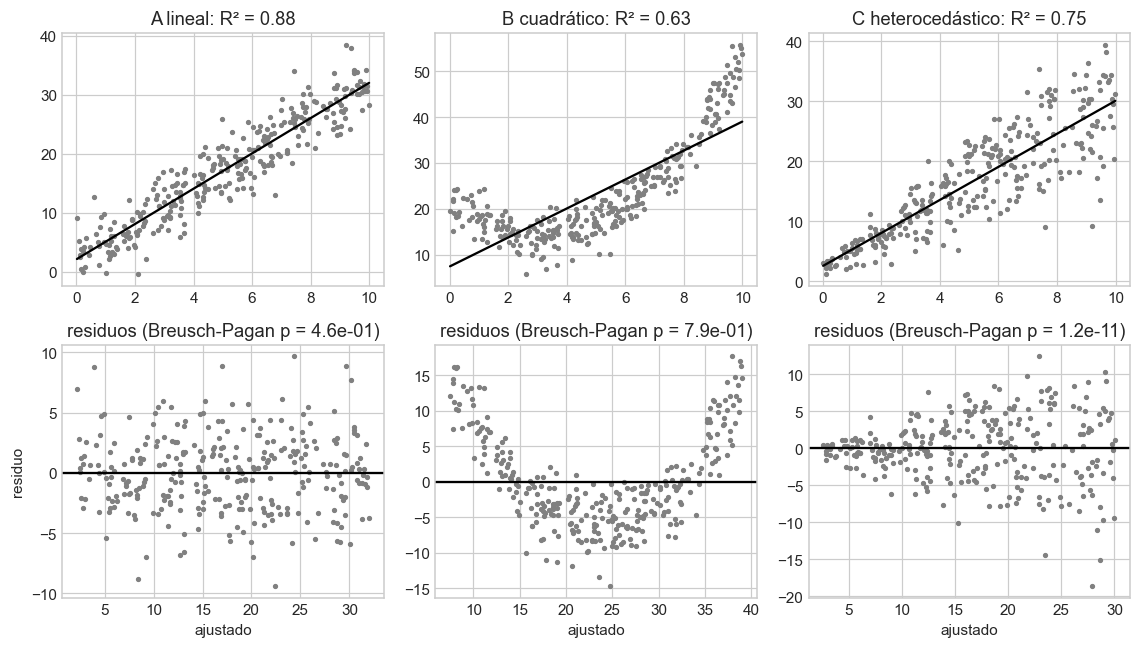

In [19]:
# Tres escenarios sintéticos con la misma parte lineal
n = 300
xs = np.sort(rng.uniform(0, 10, n))
y_A = 2 + 3 * xs + rng.normal(0, 3, n)  # A: lineal y homocedástico
y_B = (
    2 + 3 * xs + 0.8 * (xs - 5) ** 2 + rng.normal(0, 3, n)
)  # B: término cuadrático oculto
y_C = 2 + 3 * xs + rng.normal(0, 0.8 * xs + 0.5, n)  # C: varianza creciente con x
escenarios = {"A lineal": y_A, "B cuadrático": y_B, "C heterocedástico": y_C}
fig, ax = plt.subplots(2, 3, figsize=(10.5, 6))
for j, (nombre, yy) in enumerate(escenarios.items()):
    res = sm.OLS(yy, sm.add_constant(xs)).fit()
    bp = het_breuschpagan(res.resid, res.model.exog)[1]
    ax[0, j].scatter(xs, yy, s=6, color="gray")
    ax[0, j].plot(xs, res.fittedvalues, color="black")
    ax[0, j].set_title(f"{nombre}: R² = {res.rsquared:.2f}")
    ax[1, j].scatter(res.fittedvalues, res.resid, s=6, color="gray")
    ax[1, j].axhline(0, color="black")
    ax[1, j].set_title(f"residuos (Breusch-Pagan p = {bp:.1e})")
    ax[1, j].set_xlabel("ajustado")
    print(
        f"{nombre:18s}: β1 = {res.params[1]:.3f} | R² = {res.rsquared:.3f} | "
        f"Durbin-Watson = {durbin_watson(res.resid):.2f} | BP p = {bp:.2e}"
    )
ax[1, 0].set_ylabel("residuo")
plt.tight_layout()
plt.show()

In [20]:
# Corrección del escenario B con un término cuadrático (regresión polinómica = regresión múltiple en x y x²)
X_pol = sm.add_constant(np.column_stack([xs, xs**2]))
res_B2 = sm.OLS(y_B, X_pol).fit()
print(
    "B con x y x²: coeficientes =",
    res_B2.params.round(3),
    f"| R² = {res_B2.rsquared:.4f} | Durbin-Watson = {durbin_watson(res_B2.resid):.2f}",
)
# Corrección del escenario C con mínimos cuadrados ponderados (WLS): pesos = 1 / varianza estimada
pesos = 1 / (0.8 * xs + 0.5) ** 2
res_C_wls = sm.WLS(y_C, sm.add_constant(xs), weights=pesos).fit()
res_C_ols = sm.OLS(y_C, sm.add_constant(xs)).fit()
print(
    f"C con MCO: β1 = {res_C_ols.params[1]:.3f} ± {res_C_ols.bse[1]:.3f} | con WLS: "
    f"β1 = {res_C_wls.params[1]:.3f} ± {res_C_wls.bse[1]:.3f}"
)

B con x y x²: coeficientes = [22.04  -5.032  0.805] | R² = 0.9275 | Durbin-Watson = 2.04
C con MCO: β1 = 2.755 ± 0.092 | con WLS: β1 = 2.817 ± 0.063


**Interpretación de resultados:** en **A** los residuos no tienen patrón y la pendiente se recupera (≈ 3). En **B** el **R²** es engañosamente alto pero los residuos dibujan una **U**: falta el término **x²**; al agregarlo el **R²** salta y el patrón desaparece. En **C** la pendiente sigue siendo insesgada, pero el **embudo** indica **heterocedasticidad**; **WLS** reduce el **error estándar**. **Moraleja:** mirar siempre el **gráfico de residuos**; el R² solo no detecta un modelo mal especificado.

# PARTE IV — ¿Sirve la Regresión para Predecir el Retorno de Mañana? (Mundo 1: ruido financiero)

## 8. Pronóstico del Retorno de SPY a un Día con Regresión Múltiple

Ahora el objetivo es **r_(t+1)** (el retorno de **mañana**) y los regresores solo pueden usar información hasta **hoy**: retornos rezagados, volatilidad reciente y cambio de volumen. La división es **cronológica** (70 % entrenamiento, 30 % prueba) y la **referencia ingenua** es predecir **0**.

In [21]:
# Características causales (solo pasado) y objetivo futuro para SPY
r = rend["SPY"].copy()
df = pd.DataFrame(
    {
        "ret_t": r,
        "ret_t1": r.shift(1),
        "ret_t2": r.shift(2),
        "ret_t3": r.shift(3),
        "ret_t4": r.shift(4),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vix": precios["^VIX"].reindex(r.index),
        "media_22": r.rolling(22).mean(),
    }
)
df["objetivo"] = r.shift(-1)  # retorno de MAÑANA
df = df.dropna()
corte = int(len(df) * 0.7)
ent, pru = df.iloc[:corte], df.iloc[corte:]
cols = [c for c in df.columns if c != "objetivo"]
print(
    "Entrenamiento:",
    len(ent),
    "días hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "días desde",
    pru.index.min().date(),
)

Entrenamiento: 1367 días hasta 2024-07-09 | Prueba: 586 días desde 2024-07-10


In [22]:
# Regresión múltiple del retorno de mañana: métricas en entrenamiento y en prueba frente a la referencia 0
reg = LinearRegression().fit(ent[cols], ent["objetivo"])
for nombre, parte in [("entrenamiento", ent), ("prueba", pru)]:
    yp = reg.predict(parte[cols])
    r2 = r2_score(parte["objetivo"], yp)
    mae = mean_absolute_error(parte["objetivo"], yp)
    mae0 = mean_absolute_error(parte["objetivo"], np.zeros(len(parte)))
    acierto = np.mean(np.sign(yp) == np.sign(parte["objetivo"]))
    print(
        f"{nombre:14s}: R² = {r2:+.4f} | MAE modelo = {mae:.4f} | MAE referencia 0 = "
        f"{mae0:.4f} | acierto de signo = {acierto:.3f}"
    )
print("Coeficientes:", dict(zip(cols, reg.coef_.round(4))))

entrenamiento : R² = +0.0687 | MAE modelo = 0.8461 | MAE referencia 0 = 0.8414 | acierto de signo = 0.505
prueba        : R² = +0.0027 | MAE modelo = 0.7127 | MAE referencia 0 = 0.6963 | acierto de signo = 0.500
Coeficientes: {'ret_t': -0.1314, 'ret_t1': 0.0848, 'ret_t2': -0.0208, 'ret_t3': -0.0843, 'ret_t4': 0.0217, 'vol_5': -0.5354, 'vol_22': 0.3051, 'vix': 0.0163, 'media_22': -0.3942}


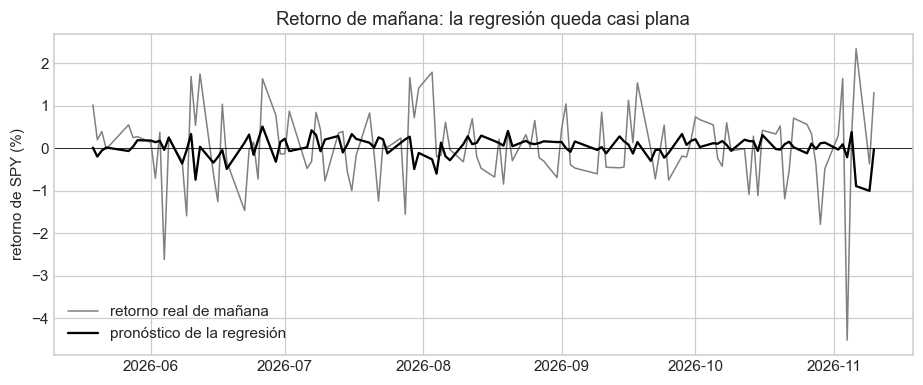

In [23]:
# Últimos 120 días de prueba: retorno real frente al pronóstico
yp = reg.predict(pru[cols])
plt.figure(figsize=(8.5, 3.6))
plt.plot(
    pru.index[-120:],
    pru["objetivo"].values[-120:],
    color="gray",
    linewidth=1,
    label="retorno real de mañana",
)
plt.plot(
    pru.index[-120:],
    yp[-120:],
    color="black",
    linewidth=1.5,
    label="pronóstico de la regresión",
)
plt.axhline(0, color="black", linewidth=0.5)
plt.ylabel("retorno de SPY (%)")
plt.legend()
plt.title("Retorno de mañana: la regresión queda casi plana")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** el **R² de prueba** es **cero o negativo**: la regresión lineal **no predice el retorno de mañana** mejor que decir **0**, y acierta el **signo** alrededor de la mitad de las veces. No es un error de código: es la **eficiencia del mercado**; el retorno diario es casi **ruido blanco**. El **R² de entrenamiento** apenas mayor que cero muestra que el modelo **memoriza** un poco, sin generalizar.

## 9. Contraste: la Volatilidad de la Próxima Semana Sí se Predice

In [24]:
# Mismas características; objetivo = volatilidad realizada de los próximos 5 días (desviación de los retornos t+1..t+5)
df_vol = df.copy()
df_vol["objetivo"] = (
    r.shift(-5).rolling(5).std().reindex(df.index)
)  # desviación de los 5 retornos futuros
df_vol = df_vol.dropna()
ent_v, pru_v = df_vol.iloc[:corte], df_vol.iloc[corte:]
reg_v = LinearRegression().fit(ent_v[cols], ent_v["objetivo"])
for nombre, parte in [("entrenamiento", ent_v), ("prueba", pru_v)]:
    yp = reg_v.predict(parte[cols])
    print(
        f"{nombre:14s}: R² = {r2_score(parte['objetivo'], yp):.4f} | MAE = "
        f"{mean_absolute_error(parte['objetivo'], yp):.4f} | "
        "MAE referencia (vol_5 de hoy) = "
        f"{mean_absolute_error(parte['objetivo'], parte['vol_5']):.4f}"
    )
print("Coeficientes:", dict(zip(cols, reg_v.coef_.round(4))))

entrenamiento : R² = 0.5769 | MAE = 0.3481 | MAE referencia (vol_5 de hoy) = 0.4363
prueba        : R² = 0.3426 | MAE = 0.3190 | MAE referencia (vol_5 de hoy) = 0.4154
Coeficientes: {'ret_t': -0.0477, 'ret_t1': -0.0668, 'ret_t2': -0.0266, 'ret_t3': -0.0198, 'ret_t4': -0.0124, 'vol_5': 0.2606, 'vol_22': 0.023, 'vix': 0.0419, 'media_22': -0.2831}


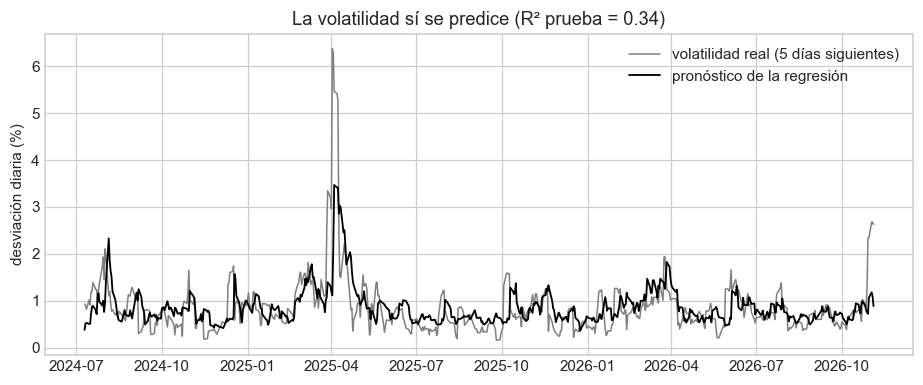

In [25]:
# Volatilidad futura real y pronosticada en la prueba
yp_v = reg_v.predict(pru_v[cols])
plt.figure(figsize=(8.5, 3.6))
plt.plot(
    pru_v.index,
    pru_v["objetivo"].values,
    color="gray",
    linewidth=1,
    label="volatilidad real (5 días siguientes)",
)
plt.plot(
    pru_v.index, yp_v, color="black", linewidth=1.2, label="pronóstico de la regresión"
)
plt.ylabel("desviación diaria (%)")
plt.legend()
plt.title(
    "La volatilidad sí se predice (R² prueba = "
    f"{r2_score(pru_v['objetivo'], yp_v):.2f})"
)
plt.tight_layout()
plt.show()

**Interpretación de resultados:** con las **mismas** variables, la regresión del **nivel de riesgo** (volatilidad de los próximos 5 días) obtiene un **R² de prueba** claramente positivo: la **volatilidad se agrupa** (días agitados siguen a días agitados) y el **VIX** la anticipa. **Moraleja:** la regresión no es «buena» o «mala»; depende de si el **objetivo** tiene **señal**. El **retorno** no la tiene; el **riesgo**, sí. Las Guías 2 y 3 mejoran este pronóstico con **regularización** y **ensambles**.

## 10. Actividad Autónoma

1. Calcule el **beta** de las 5 **mineras** frente a **GLD** (oro) en lugar de SPY y compare el **R²** con el de la tabla de la sección 4. ¿Cuál de ellas es «más oro» y cuál «más cobre» (use **SCCO** como referencia del cobre)?
2. Repita el modelo de mercado de **AAPL** en dos períodos: **2019–2021** y **2022–2026**. ¿Cambia el beta? ¿Se solapan los **intervalos de confianza**?
3. En la sección 8 agregue el **retorno de QQQ** de hoy como regresor y verifique que el **R² de prueba** sigue siendo ≈ 0 (no hay fuga: QQQ de hoy ya se conoce al cierre).

**Entregable:** notebook ejecutado con una tabla de betas frente a GLD y un párrafo (≤ 150 palabras) sobre qué supuesto de MCO se viola con más claridad en los datos financieros.